In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
transactions = pd.read_csv('../data/processed/transactions.csv', parse_dates=['invoice_date'])
customers = pd.read_csv('../data/processed/customers.csv')
products = pd.read_csv('../data/processed/products.csv')
print('transactions:', transactions.shape)
print('customers :', customers.shape)

transactions: (776629, 8)
customers : (5861, 2)


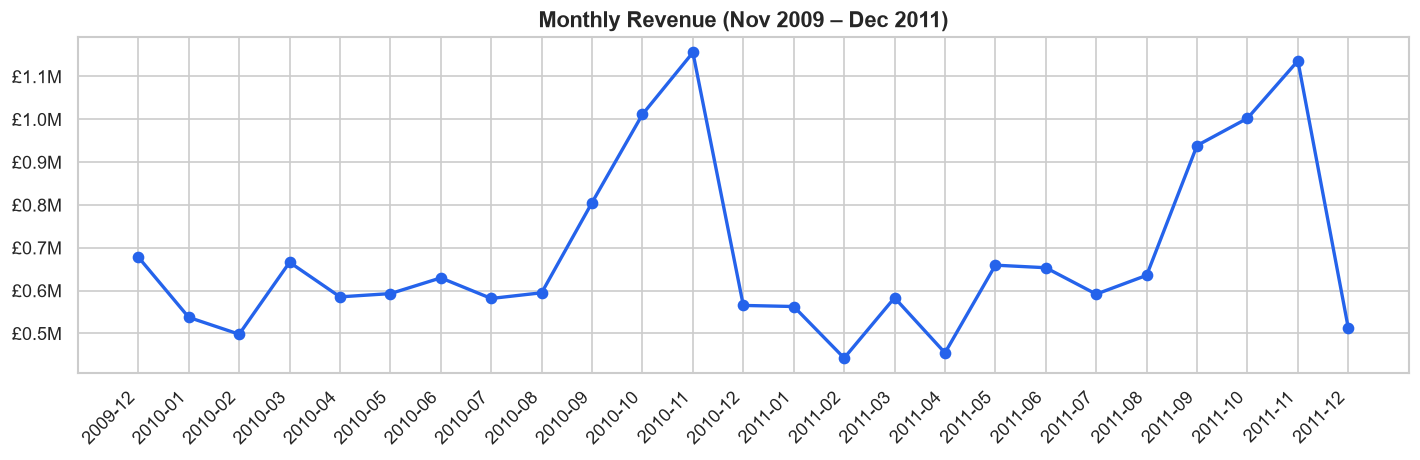

In [2]:
monthly = (transactions[transactions['is_cancellation']==False]
.groupby(transactions['invoice_date'].dt.to_period('M'))
['line_revenue'].sum()
.reset_index())
monthly['invoice_date'] = monthly['invoice_date'].astype(str)
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(monthly['invoice_date'], monthly['line_revenue'],
marker='o', linewidth=2, color='#2563EB')
ax.set_title('Monthly Revenue (Nov 2009 – Dec 2011)', fontsize=13, fontweight='bold')
ax.set_xlabel('')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'£{x/1e6:.1f}M'))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/01_monthly_revenue.png', bbox_inches='tight')
plt.show()

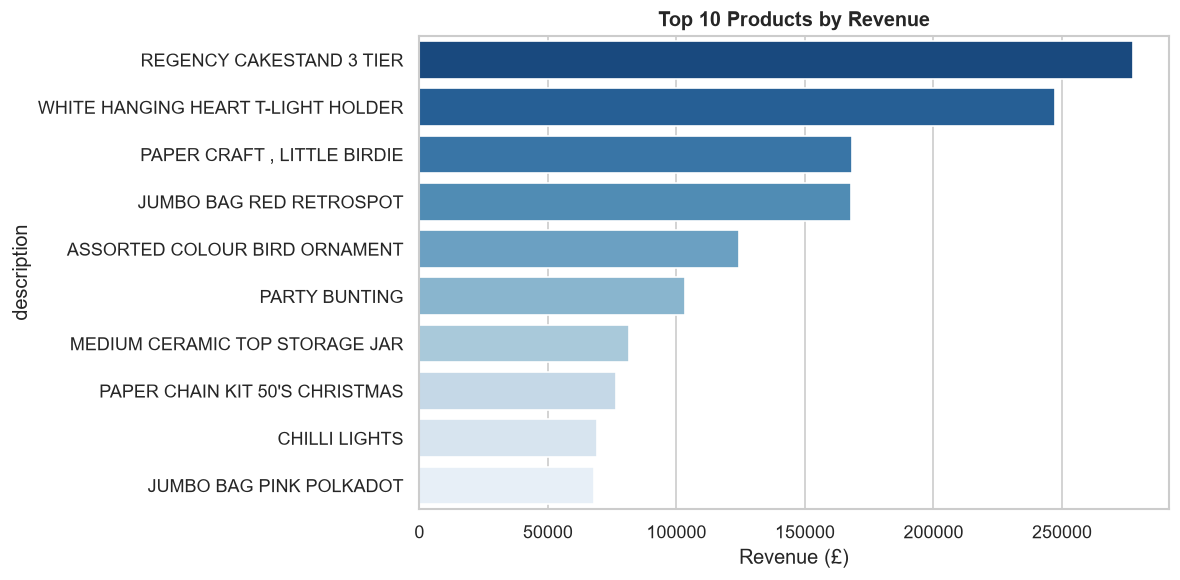

In [3]:
sales = transactions[transactions['is_cancellation']==False].copy()
sales = sales.merge(products, on='stock_code', how='left')
top_products = (sales.groupby('description')['line_revenue'].sum()
.sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(x=top_products.values, y=top_products.index, ax=ax, palette='Blues_r')
ax.set_title('Top 10 Products by Revenue', fontweight='bold')
ax.set_xlabel('Revenue (£)')
plt.tight_layout()
plt.savefig('../reports/figures/02_top_products.png', bbox_inches='tight')
plt.show()


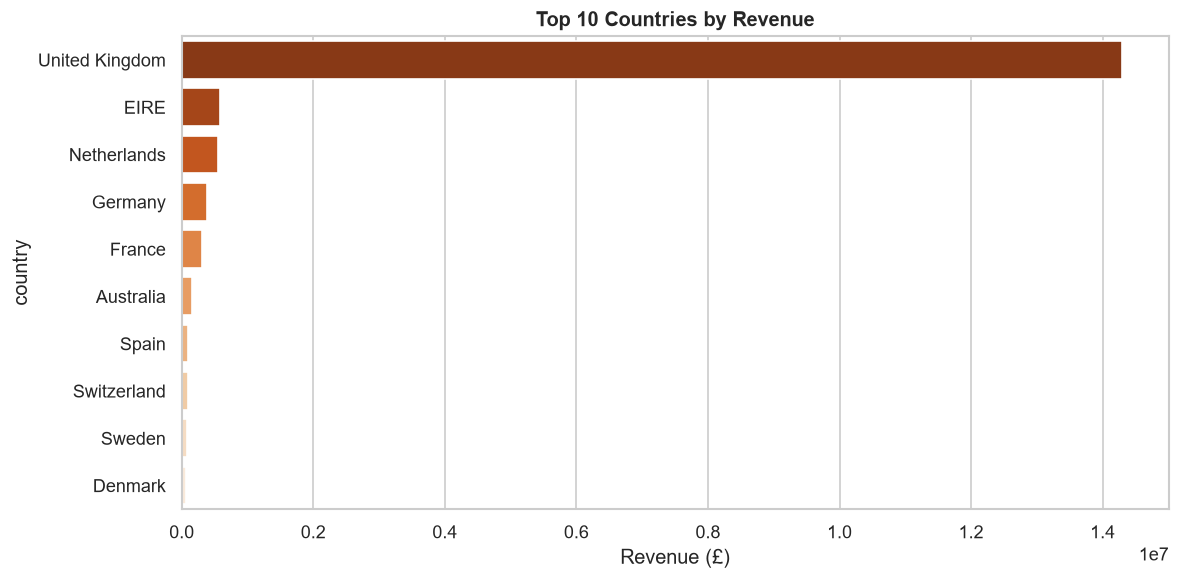

In [4]:
sales_c = sales.merge(customers, on='customer_id', how='left')
top_countries = (sales_c.groupby('country')['line_revenue'].sum()
.sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(x=top_countries.values, y=top_countries.index, ax=ax, palette='Oranges_r')
ax.set_title('Top 10 Countries by Revenue', fontweight='bold')
ax.set_xlabel('Revenue (£)')
plt.tight_layout()
plt.savefig('../reports/figures/03_revenue_by_country.png', bbox_inches='tight')
plt.show()


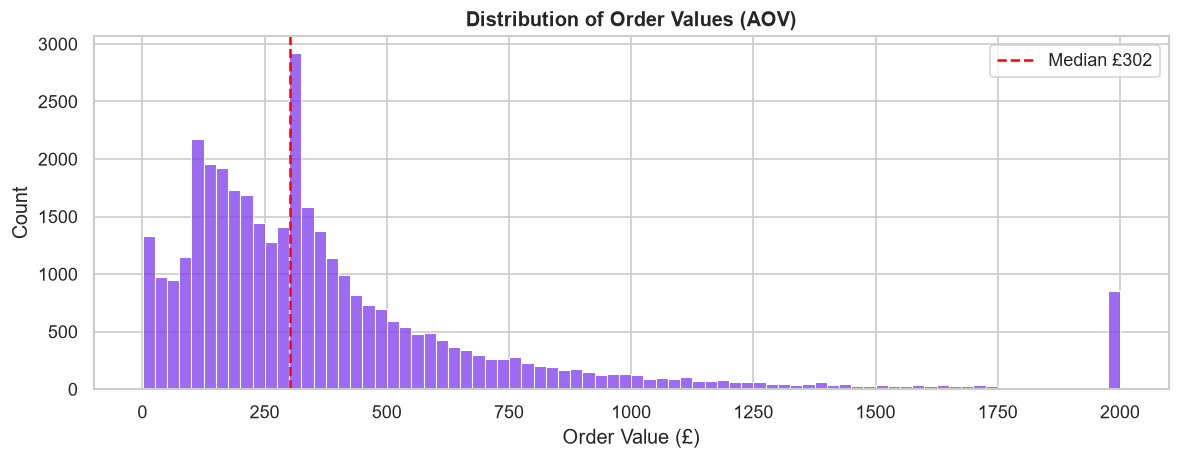

In [5]:
order_values = (sales.groupby('invoice')['line_revenue'].sum()
.clip(upper=2000)) # clip outliers for readability
fig, ax = plt.subplots(figsize=(10,4))
sns.histplot(order_values, bins=80, ax=ax, color='#7C3AED')
ax.set_title('Distribution of Order Values (AOV)', fontweight='bold')
ax.set_xlabel('Order Value (£)')
ax.axvline(order_values.median(), color='red', linestyle='--',
label=f'Median £{order_values.median():.0f}')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/04_order_distribution.png', bbox_inches='tight')
plt.show()

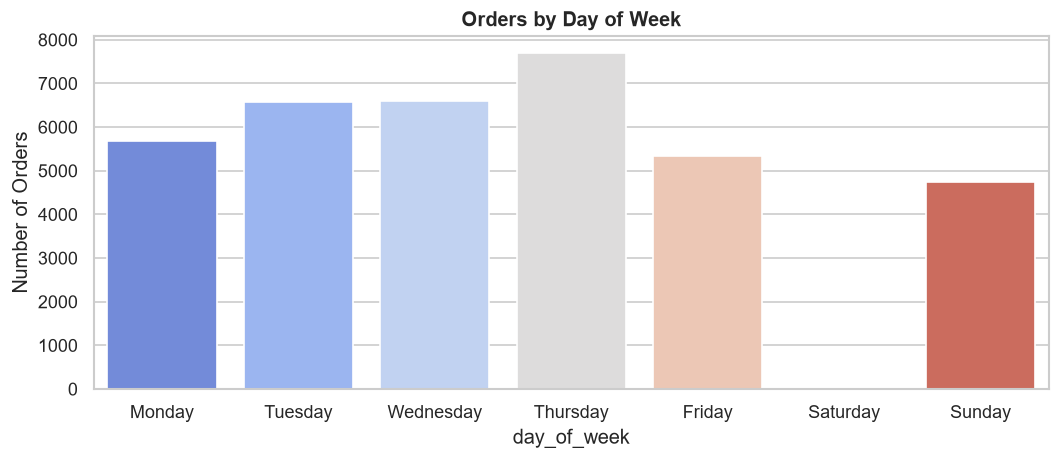

In [6]:
sales['day_of_week'] = sales['invoice_date'].dt.day_name()
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_counts = (sales.groupby('day_of_week')['invoice'].nunique()
.reindex(day_order))
fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(x=day_counts.index, y=day_counts.values, ax=ax, palette='coolwarm')
ax.set_title('Orders by Day of Week', fontweight='bold')
ax.set_ylabel('Number of Orders')
plt.tight_layout()
plt.savefig('../reports/figures/05_orders_by_day.png', bbox_inches='tight')
plt.show()


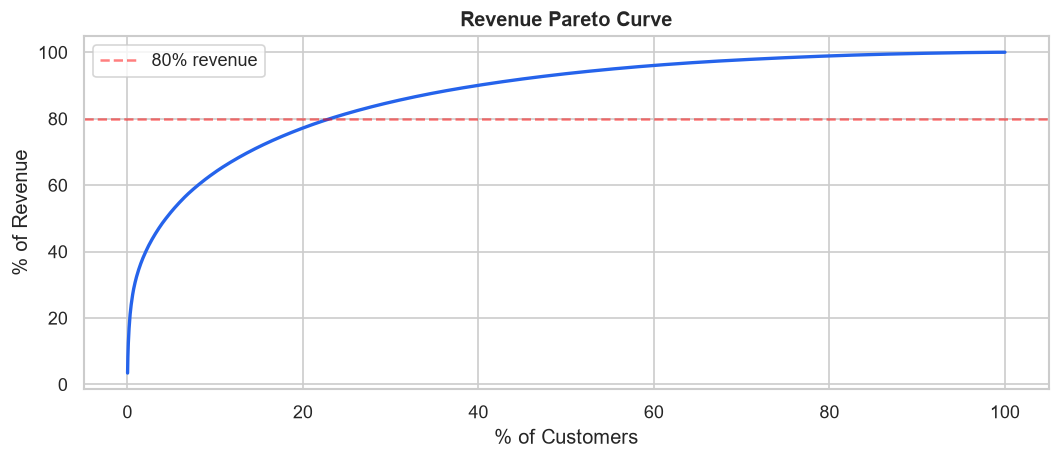

In [8]:
cust_revenue = (sales.groupby('customer_id')['line_revenue'].sum()
.sort_values(ascending=False))
cust_revenue_pct = cust_revenue.cumsum() / cust_revenue.sum() * 100
cust_pct = np.arange(1, len(cust_revenue)+1) / len(cust_revenue) * 100
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(cust_pct, cust_revenue_pct, color='#2563EB', linewidth=2)
ax.axhline(80, color='red', linestyle='--', alpha=0.5, label='80% revenue')
ax.set_title('Revenue Pareto Curve', fontweight='bold')
ax.set_xlabel('% of Customers')
ax.set_ylabel('% of Revenue')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/06_pareto.png', bbox_inches='tight')
plt.show()
